# Company Bankruptcy Prediction — Final ML Pipeline
IT2011 Artificial Intelligence and Machine Learning — Final Evaluation

**Group ID:** 2026-Y2-S1-MET-16

This is the **one master notebook** for the final evaluation, the demo and the viva. It does five jobs, in this order:

| Step | What it does | Why |
|---|---|---|
| 1 | Re-runs the group's preprocessing on `data/raw/data.csv` and saves everything needed to repeat it | So a **new company in raw units** can be given to the model *exactly* like the training data |
| 2 | Loads `train_set.csv` / `test_set.csv` and checks they match step 1 | Proves the files and the code agree |
| 3 | Trains the **six models** with their tuned settings | Same data, same split → a fair comparison |
| 4 | Evaluates them: test set, 5-fold cross-validation, curves | Real numbers, no copy-pasted results |
| 5 | Picks the best model **from those numbers**, saves it, and predicts new companies from raw ratios | The demo |

**Every number in this notebook is computed when you press *Run all*.** Nothing is typed in by hand.

## Import Libraries

In [1]:
import sys, os, json, time, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')       # keep the output clean for screenshots
sns.set(color_codes=True)
pd.set_option('display.max_columns', None)
%matplotlib inline

## Settings and Folder Paths
**Why a settings cell?** Everything you might want to change is in this one cell, so in the viva you can point at it and say what each switch does.

- `SEED = 42` — every random step (CV folds, model seeds) uses the same number, so **the results are the same on every run**.
- `RUN_GRID_SEARCH` — `False` uses the tuned settings we already found in the six model notebooks (fast, ~1 minute). `True` repeats the whole GridSearchCV for all six models (slow, 10+ minutes).
- `DECISION_THRESHOLD = 0.5` — the cut-off used when the final model says "bankrupt". We keep the default 0.5 so the numbers match the six model notebooks and the viva guide.

In [2]:
SEED = 42
RUN_GRID_SEARCH = False
DECISION_THRESHOLD = 0.5
TARGET = 'Bankrupt?'
np.random.seed(SEED)

# --- find the project folder, whether we run from the root or from a sub-folder -----------
def find_project_root():
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / 'data' / 'raw' / 'data.csv').exists():
            return p
    raise FileNotFoundError("Open this notebook inside the project folder (the one that has data/raw/data.csv). "
                            "In Google Colab: upload the whole folder, then run  %cd <folder name>")

ROOT       = find_project_root()
RAW_CSV    = ROOT / 'data' / 'raw' / 'data.csv'
SAMPLE_CSV = ROOT / 'data' / 'external' / 'sample_data_example.csv'   # new companies in RAW units
OUT_DIR    = ROOT / 'results' / 'outputs'
FIG_DIR    = ROOT / 'results' / 'eda_visualizations'
LOG_DIR    = ROOT / 'results' / 'logs'
for d in (OUT_DIR, FIG_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- log file: a written record of every run (goes to results/logs/) --------------------
log = logging.getLogger('pipeline')
log.setLevel(logging.INFO)
log.handlers.clear()                     # avoids double lines if the cell is run twice
for h in (logging.FileHandler(LOG_DIR / 'pipeline_run.log', mode='w', encoding='utf-8'),
          logging.StreamHandler(sys.stdout)):
    h.setFormatter(logging.Formatter('%(asctime)s | %(message)s', '%H:%M:%S'))
    log.addHandler(h)

def save_fig(name):
    # every plot is saved as a PNG for the report
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

log.info(f'Project folder: {ROOT.name}')
log.info(f'SEED={SEED} | RUN_GRID_SEARCH={RUN_GRID_SEARCH} | DECISION_THRESHOLD={DECISION_THRESHOLD}')

09:15:19 | Project folder: 2026-Y2-S1-MET-16


09:15:19 | SEED=42 | RUN_GRID_SEARCH=False | DECISION_THRESHOLD=0.5


---
## Step 1: Preprocessing — repeat the group pipeline and remember every number
**What we do:** we run the same six techniques as `group_pipeline.ipynb`, in the same order, on `data/raw/data.csv`:

1. remove the constant column `Net Income Flag` and strip the spaces in the column names
2. drop duplicate rows and missing values (there are none, but the check is required)
3. remove IQR outliers — only from the **healthy** companies and only on the 5 columns most correlated with the target, so that **all 220 bankrupt companies stay**
4. MinMax-scale every column to 0–1
5. drop the 32 columns whose correlation with `Bankrupt?` is below 0.02
6. add the new column `Profitability Ratio = ROA(C) / (ROA(A) + 0.0001)`

**Why do it again here if train/test files already exist?** A *new* company arrives in **raw** units (for example "Debt ratio % = 0.12"). The model only understands the **scaled** numbers. To convert it correctly we need the exact `min` and `max` of every column, the list of columns we kept, and the order of the columns. `fit_preprocessing()` returns all of them in the dictionary `art` (short for *artifacts*) and we save it to `results/outputs/preprocessing_artifacts.json`.

In [3]:
def fit_preprocessing(raw):
    # Repeats the group's six techniques and returns (final_df, art).
    d = raw.copy()
    d.columns = d.columns.str.strip()                    # header names had leading spaces

    # 1) constant column: same value in every row -> carries no information
    d = d.drop(columns=['Net Income Flag'])

    # 2) duplicates and missing values (none in this dataset, but we always check)
    d = d.drop_duplicates().dropna()

    # 3) IQR outliers: only on the 5 columns most correlated with the target and ONLY on healthy
    #    rows. Why? IQR on all 90+ columns would delete almost every row, and bankrupt companies
    #    look 'extreme' by nature - we must not throw away our rare class.
    corr_t   = d.corr(numeric_only=True)[TARGET].drop(TARGET).abs().sort_values(ascending=False)
    iqr_cols = list(corr_t.head(5).index)
    healthy, bankrupt = d[d[TARGET] == 0], d[d[TARGET] == 1]
    q1, q3 = healthy[iqr_cols].quantile(0.25), healthy[iqr_cols].quantile(0.75)
    iqr    = q3 - q1
    inside = ~((healthy[iqr_cols] < q1 - 1.5 * iqr) | (healthy[iqr_cols] > q3 + 1.5 * iqr)).any(axis=1)
    d = pd.concat([healthy[inside], bankrupt]).sort_index()

    # 4) MinMax scaling: (x - min) / (max - min). We store min and max because a new company
    #    must be scaled with THESE numbers, not with its own.
    X, y = d.drop(columns=[TARGET]), d[TARGET]
    col_min, col_max = X.min(), X.max()
    Xs = (X - col_min) / (col_max - col_min)

    # 5) drop columns that barely move with the target (|correlation| < 0.02)
    corr_s = pd.concat([Xs, y.rename('Target')], axis=1).corr()['Target'].drop('Target').abs()
    low_corr = list(corr_s[corr_s < 0.02].index)
    Xs = Xs.drop(columns=low_corr)
    kept_raw = list(Xs.columns)                          # the raw columns the model really uses

    # 6) new ratio feature, built from the already scaled columns (same as the group notebook)
    Xs['Profitability Ratio'] = (Xs['ROA(C) before interest and depreciation before interest']
                                 / (Xs['ROA(A) before interest and % after tax'] + 0.0001))

    final = Xs.assign(**{TARGET: y.values})
    art = {
        'iqr_columns': iqr_cols,
        'low_corr_dropped': low_corr,
        'kept_raw_columns': kept_raw,
        'feature_order': list(Xs.columns),               # 62 kept + Profitability Ratio = 63
        'scaler_min': {c: float(col_min[c]) for c in kept_raw},
        'scaler_max': {c: float(col_max[c]) for c in kept_raw},
        'raw_median': {c: float(X[c].median()) for c in kept_raw},   # used to fill ratios a user leaves out
    }
    return final, art

raw = pd.read_csv(RAW_CSV)
log.info(f'Raw data: {raw.shape[0]} rows x {raw.shape[1]} columns')
final_df, art = fit_preprocessing(raw)

log.info(f'After preprocessing: {final_df.shape[0]} rows x {final_df.shape[1]} columns '
         f'({len(art["feature_order"])} features + target)')
log.info(f'Bankrupt companies kept: {int(final_df[TARGET].sum())} of {int((raw[TARGET] == 1).sum())}')
log.info(f'IQR columns: {art["iqr_columns"]}')
log.info(f'Columns dropped for low correlation: {len(art["low_corr_dropped"])}')

with open(OUT_DIR / 'preprocessing_artifacts.json', 'w', encoding='utf-8') as f:
    json.dump(art, f, indent=2, ensure_ascii=False)

09:15:19 | Raw data: 6819 rows x 96 columns


09:15:19 | After preprocessing: 6198 rows x 64 columns (63 features + target)


09:15:19 | Bankrupt companies kept: 220 of 220


09:15:19 | IQR columns: ['Net Income to Total Assets', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'ROA(C) before interest and depreciation before interest', 'Net worth/Assets']


09:15:19 | Columns dropped for low correlation: 32


**Check:** the dataset we just rebuilt must be the same as the one the group saved (`final_processed_data.csv`). If this cell passes, the preprocessing code above is the *real* preprocessing behind the train/test files.

In [4]:
saved_final = pd.read_csv(OUT_DIR / 'final_processed_data.csv')
assert list(saved_final.columns) == list(final_df.columns), 'column names/order differ'
assert saved_final.shape == final_df.shape, 'shape differs'
max_diff = np.abs(saved_final.values - final_df.values.astype(float)).max()
assert max_diff < 1e-9, f'values differ by {max_diff}'
log.info(f'Check passed: rebuilt data == final_processed_data.csv (largest difference {max_diff:.1e})')

09:15:19 | Check passed: rebuilt data == final_processed_data.csv (largest difference 1.3e-15)


---
## Step 2: Load the train and test sets
**What we do:** read `train_set.csv` and `test_set.csv` (made by the group pipeline, 80 % / 20 %, stratified), split them into inputs `X` and answer `y`, and look at the class balance.

**Why stratified?** Only about 3.5 % of the companies are bankrupt. A plain random split could leave the test set with very few of them. Stratifying keeps the 3.5 % in both sets.

09:15:20 | Check passed: train_set.csv / test_set.csv == a stratified 80/20 split of the rebuilt data (seed 42)


09:15:20 | Train: (4958, 63) | Test: (1240, 63)


09:15:20 | Train healthy=4782, bankrupt=176 (3.55%) | Test healthy=1196, bankrupt=44 (3.55%)


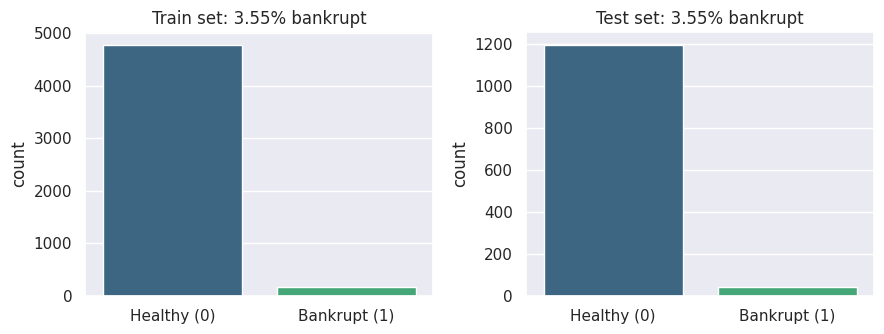

In [5]:
train = pd.read_csv(OUT_DIR / 'train_set.csv')
test  = pd.read_csv(OUT_DIR / 'test_set.csv')

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET].astype(int)
X_test,  y_test  = test.drop(columns=[TARGET]),  test[TARGET].astype(int)

# the model must receive the columns in exactly the order used in Step 1
assert list(X_train.columns) == art['feature_order'] == list(X_test.columns)
assert train.isnull().sum().sum() == 0 and test.isnull().sum().sum() == 0

# the saved split must be the split we get when we repeat it with the same seed
Xa, Xb, ya, yb = train_test_split(final_df.drop(columns=[TARGET]), final_df[TARGET],
                                  test_size=0.2, random_state=SEED, stratify=final_df[TARGET])
assert np.allclose(Xa.values, X_train.values) and np.allclose(Xb.values, X_test.values)
log.info('Check passed: train_set.csv / test_set.csv == a stratified 80/20 split of the rebuilt data (seed 42)')

neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = neg / pos            # about 27 healthy companies for every bankrupt one
log.info(f'Train: {X_train.shape} | Test: {X_test.shape}')
log.info(f'Train healthy={neg}, bankrupt={pos} ({y_train.mean()*100:.2f}%) | '
         f'Test healthy={int((y_test==0).sum())}, bankrupt={int(y_test.sum())} ({y_test.mean()*100:.2f}%)')

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=False)
for a, (nm, yy) in zip(ax, [('Train', y_train), ('Test', y_test)]):
    sns.countplot(x=yy, ax=a, palette='viridis')
    a.set_title(f'{nm} set: {yy.mean()*100:.2f}% bankrupt')
    a.set_xticklabels(['Healthy (0)', 'Bankrupt (1)'])
    a.set_xlabel('')
plt.tight_layout(); save_fig('plot_01_class_distribution.png'); plt.show()

**What this tells us:** the data is **imbalanced** — 176 bankrupt vs 4,782 healthy companies in training (about 1 : 27), and only **44 bankrupt companies in the test set**.

**Why this matters:**
- a lazy model that says "healthy" every time is ~96.5 % accurate but catches **zero** bankruptcies, so **accuracy is a bad score here**. We use **recall, precision, F1, ROC-AUC and PR-AUC** of the bankrupt class.
- with only 44 bankrupt test companies, **one company changes recall by about 2.3 points**. Small differences between models are noise.

---
## Step 3: The six models and their settings
**What we do:** build the six models with the **tuned settings** found by `GridSearchCV` in the six model notebooks in `notebooks/`. Each grid was scored with **PR-AUC** on 3-fold cross-validation of the **training set only**.

**Why the same settings in every notebook and here?** So the comparison is fair and the numbers can be reproduced.

**How each model handles the 1 : 27 imbalance** (otherwise every model mostly learns the healthy companies):

| Model | Imbalance fix | Why this fix |
|---|---|---|
| SVM | `class_weight='balanced'` | a mistake on a bankrupt company costs ~27× more |
| XGBoost | `scale_pos_weight` = healthy ÷ bankrupt | XGBoost's own built-in version of the same idea |
| KNN | `weights='distance'` | **not a real fix** — closer neighbours count more, but the healthy majority still wins most votes |
| Gradient Boosting | balanced **sample weights** inside `fit()` | the sklearn class has no class-weight option, so we pass the weights ourselves |
| AdaBoost | balanced **sample weights** inside `fit()` | the starting weights of the bankrupt companies are already ~27× bigger |
| Naive Bayes | `priors=[0.5, 0.5]` | tells the model both classes are equally likely before it sees the data |

In [6]:
class BalancedGB(GradientBoostingClassifier):
    # GradientBoostingClassifier has no class_weight option, so we give every company a weight
    # that is inversely proportional to its class size (bankrupt rows weigh ~27x more).
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y))

class BalancedAda(AdaBoostClassifier):
    # same idea for AdaBoost: the very first stumps already focus on the bankrupt companies
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y))

def make_models(spw):
    return {
        # C=1: normal strictness. gamma=0.05: smooth boundary. probability=True is needed for ROC/PR-AUC.
        'SVM': SVC(kernel='rbf', C=1, gamma=0.05, class_weight='balanced',
                   probability=True, random_state=SEED),
        # 300 very shallow trees (depth 2) learning slowly (0.03): the combination chosen to avoid overfitting
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=2,
                                 scale_pos_weight=spw, eval_metric='logloss',
                                 random_state=SEED, n_jobs=-1),
        # k=25: look at 25 similar companies (a bigger k is less noisy); closer ones count more
        'KNN': KNeighborsClassifier(n_neighbors=25, weights='distance'),
        'Gradient Boosting': BalancedGB(n_estimators=100, learning_rate=0.05, max_depth=3,
                                        random_state=SEED),
        'AdaBoost': BalancedAda(n_estimators=200, learning_rate=0.1, random_state=SEED),
        # var_smoothing=1e-3 adds a little variance to every feature, which softens the
        # 'features are independent' assumption (our ratios are strongly correlated)
        'Naive Bayes': GaussianNB(priors=[0.5, 0.5], var_smoothing=1e-3),
    }

# the grids used in the six model notebooks (only used when RUN_GRID_SEARCH = True)
GRIDS = {
    'SVM':               {'C': [0.5, 1, 5, 10], 'gamma': ['scale', 0.01, 0.05]},
    'XGBoost':           {'n_estimators': [100, 300], 'max_depth': [2, 4, 6], 'learning_rate': [0.03, 0.1]},
    'KNN':               {'n_neighbors': [3, 5, 9, 15, 25]},
    'Gradient Boosting': {'n_estimators': [100, 150], 'max_depth': [2, 3], 'learning_rate': [0.05, 0.1]},
    'AdaBoost':          {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]},
    'Naive Bayes':       {'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]},
}

def tune_models(models, X, y, only=None):
    # GridSearchCV: tries every combination, scores it with 3-fold CV on the TRAINING set
    # (never the test set) using PR-AUC, and keeps the best combination.
    cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    for name, grid in GRIDS.items():
        if only and name not in only:
            continue
        est = clone(models[name])
        if name == 'SVM':
            est.set_params(probability=False)      # much faster; probabilities are not needed to rank grids
        t = time.time()
        gs = GridSearchCV(est, grid, scoring='average_precision', cv=cv3, n_jobs=-1).fit(X, y)
        models[name].set_params(**gs.best_params_)
        log.info(f'GridSearch {name}: best {gs.best_params_} | CV PR-AUC {gs.best_score_:.3f} | {time.time()-t:.0f}s')
    return models

models = make_models(spw)
if RUN_GRID_SEARCH:
    models = tune_models(models, X_train, y_train)

pd.DataFrame({n: {k: v for k, v in m.get_params().items()
                  if k in ('C', 'gamma', 'n_estimators', 'learning_rate', 'max_depth', 'n_neighbors',
                           'weights', 'var_smoothing', 'class_weight', 'scale_pos_weight')}
              for n, m in models.items()}).T.fillna('')

,C,class_weight,gamma,learning_rate,max_depth,n_estimators,scale_pos_weight,n_neighbors,weights,var_smoothing
SVM,1,balanced,0.05,,,,,,,
XGBoost,,,,0.03,2.0,300.0,27.170455,,,
KNN,,,,,,,,25,distance,
Gradient Boosting,,,,0.05,3.0,100.0,,,,
AdaBoost,,,,0.1,,200.0,,,,
Naive Bayes,,,,,,,,,,0.001


---
## Step 4: Train all six models and test them
**What we do:** `fit()` every model on the **train set**, then predict the **test set** (companies the model has never seen).

**Scores (all for the bankrupt class):**
- **Recall** — of the really bankrupt companies, how many did we catch?
- **Precision** — of the companies we flagged, how many were really bankrupt?
- **F1** — one number that is high only if both recall and precision are good
- **ROC-AUC / PR-AUC** — how well the model **ranks** risky companies above safe ones for *all* cut-offs. **PR-AUC** is fairer for rare classes, so it is our main score.
- **Train F1 vs Test F1** — a big gap means **overfitting** (memorising the training data)

In [7]:
def evaluate(name, model):
    # all scores on the TEST set + Train F1 for the overfitting check
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'Model': name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob),
            'PR-AUC': average_precision_score(y_test, prob),
            'Train F1': f1_score(y_train, model.predict(X_train)),
            'Caught (of %d)' % y_test.sum(): int(tp),
            'False alarms': int(fp)}

test_rows, fit_times = [], {}
for name, model in models.items():
    t = time.time()
    model.fit(X_train, y_train)
    fit_times[name] = time.time() - t
    test_rows.append(evaluate(name, model))
    log.info(f'Trained {name:<18} in {fit_times[name]:5.1f}s')

test_table = pd.DataFrame(test_rows).set_index('Model')
display(test_table.round(3))

09:15:25 | Trained SVM                in   3.9s


09:15:26 | Trained XGBoost            in   0.8s


09:15:26 | Trained KNN                in   0.0s


09:15:34 | Trained Gradient Boosting  in   7.7s


09:15:41 | Trained AdaBoost           in   6.4s


09:15:41 | Trained Naive Bayes        in   0.0s


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train F1,Caught (of 44),False alarms
Model,,,,,,,,,
SVM,0.892,0.232,0.886,0.368,0.964,0.665,0.350,39,129
XGBoost,0.926,0.303,0.841,0.446,0.968,0.791,0.488,37,85
KNN,0.970,1.000,0.159,0.275,0.865,0.527,1.000,7,0
Gradient Boosting,0.931,0.319,0.818,0.459,0.958,0.713,0.536,36,77
AdaBoost,0.897,0.244,0.909,0.385,0.963,0.699,0.374,40,124
Naive Bayes,0.963,0.469,0.341,0.395,0.898,0.400,0.527,15,17


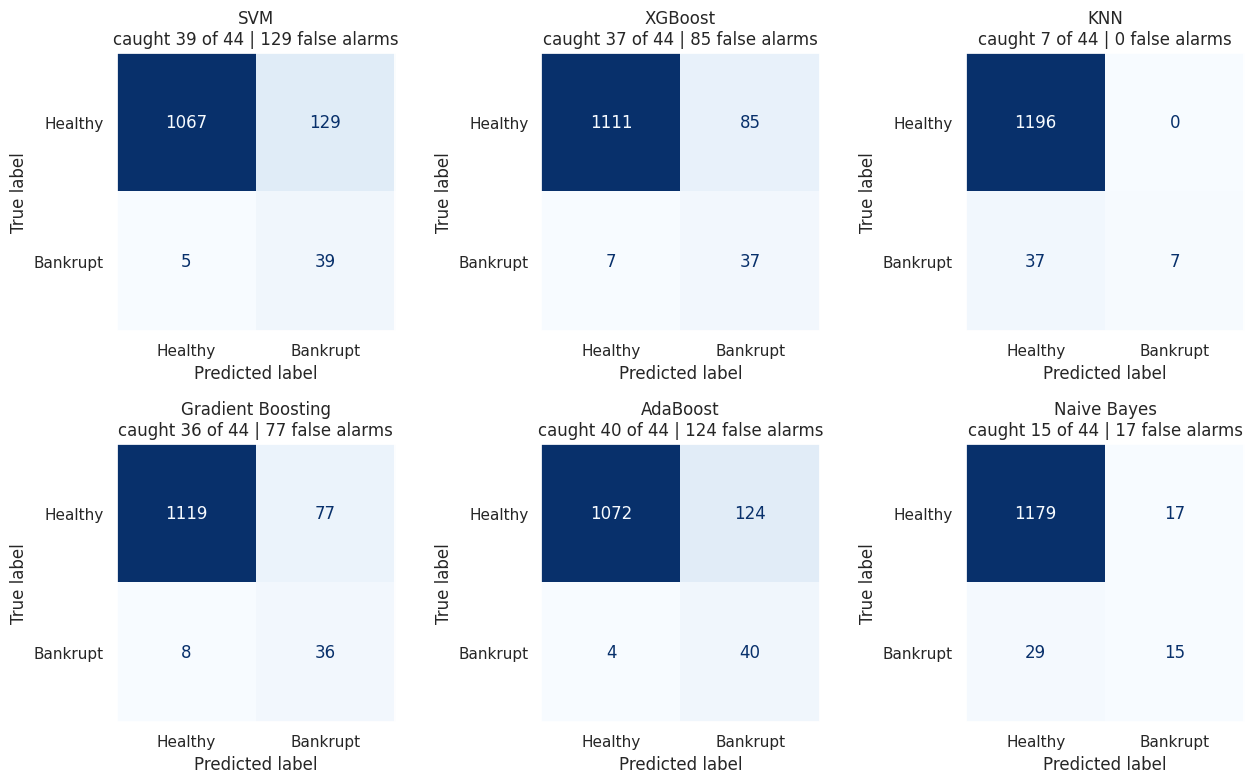

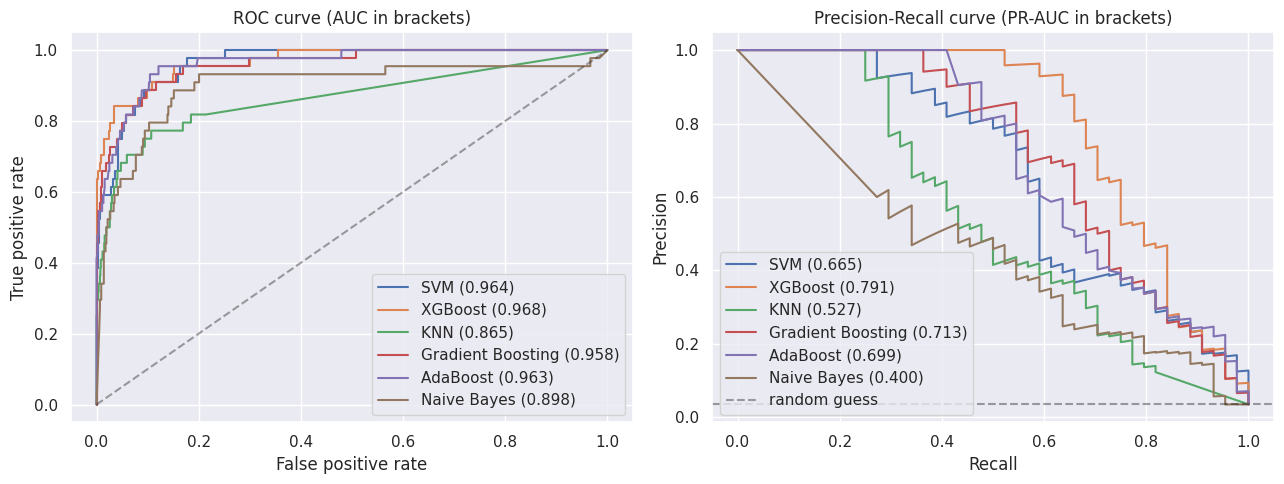

In [8]:
# confusion matrices: rows = real answer, columns = model answer
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'Bankrupt']).plot(ax=ax, cmap='Blues',
                                                                           values_format='d', colorbar=False)
    ax.set_title(f'{name}\ncaught {cm[1,1]} of {cm[1].sum()} | {cm[0,1]} false alarms')
    ax.grid(False)
plt.tight_layout(); save_fig('plot_02_confusion_matrices.png'); plt.show()

# ROC and Precision-Recall curves of all six models in one picture
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    pr, rc, _   = precision_recall_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_test, prob):.3f})')
    ax[1].plot(rc, pr,   label=f'{name} ({average_precision_score(y_test, prob):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[0].set(title='ROC curve (AUC in brackets)', xlabel='False positive rate', ylabel='True positive rate')
ax[1].axhline(y_test.mean(), color='k', ls='--', alpha=0.4, label='random guess')
ax[1].set(title='Precision-Recall curve (PR-AUC in brackets)', xlabel='Recall', ylabel='Precision')
ax[0].legend(); ax[1].legend()
plt.tight_layout(); save_fig('plot_03_roc_pr_curves.png'); plt.show()

**How to read the curves:** ROC closer to the top-left corner is better. In the PR curve the dashed line is a model that guesses at random (precision = 3.5 %); the higher a curve stays as recall grows, the better. **The PR curve separates the models more clearly than the ROC curve**, which is why PR-AUC is our main score.

,Train F1,Test F1,Gap
Model,,,
SVM,0.350,0.368,-0.018
XGBoost,0.488,0.446,0.042
KNN,1.000,0.275,0.725
Gradient Boosting,0.536,0.459,0.078
AdaBoost,0.374,0.385,-0.010
Naive Bayes,0.527,0.395,0.132


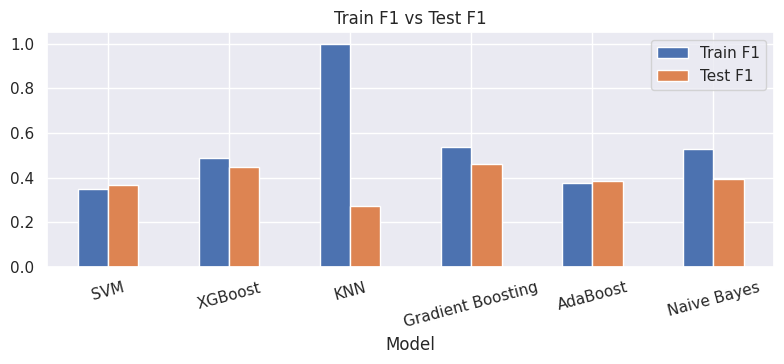

In [9]:
# overfitting check: Train F1 against Test F1
gap = test_table[['Train F1', 'F1']].rename(columns={'F1': 'Test F1'})
gap['Gap'] = gap['Train F1'] - gap['Test F1']
display(gap.round(3))
gap[['Train F1', 'Test F1']].plot(kind='bar', figsize=(8, 3.8), title='Train F1 vs Test F1')
plt.xticks(rotation=15); plt.tight_layout(); save_fig('plot_04_train_vs_test_f1.png'); plt.show()

**How to read it:**
- Train F1 **much higher** than test F1 → **overfitting** (like a student who learned last year's answers by heart).
- Both **low and close** → **underfitting** (the model is too simple).
- KNN with `weights='distance'` always shows Train F1 = 1.0: every training company is its own nearest neighbour at distance 0. That is **not** real overfitting; it is a side effect of distance weighting.

---
## Step 5: Stratified 5-fold cross-validation (the fair way to choose)
**What we do:** cut the **training set** into 5 parts (*folds*). Train on 4, score on the 5th, repeat 5 times so every part is the validation part once. *Stratified* keeps ~3.5 % bankrupt companies in every fold.

**Why do we need it when we already have a test set?** The test set has only 44 bankrupt companies, so one lucky or unlucky company moves the scores a lot. Cross-validation uses **many more bankrupt companies for scoring** (176 across the folds) and the **test set is not touched**. That is why we will choose the best model with the **CV PR-AUC** and use the test set only as the final check.

**Same protocol for all six:** every model is cross-validated with its *tuned* settings. (The six model notebooks cross-validated slightly different versions of each model, so their CV numbers are not directly comparable.)

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows, oof_prob = [], {}          # oof_prob = out-of-fold probabilities, used later for the threshold study

for name, model in models.items():
    t = time.time()
    oof = np.zeros(len(y_train))
    for fold, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
        m = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        yv, pred, prob = y_train.iloc[va], m.predict(X_train.iloc[va]), m.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = prob
        cv_rows.append({'Model': name, 'fold': fold,
                        'Recall': recall_score(yv, pred), 'Precision': precision_score(yv, pred, zero_division=0),
                        'F1': f1_score(yv, pred), 'ROC-AUC': roc_auc_score(yv, prob),
                        'PR-AUC': average_precision_score(yv, prob)})
    oof_prob[name] = oof
    log.info(f'5-fold CV {name:<18} done in {time.time()-t:5.1f}s')

cv_folds = pd.DataFrame(cv_rows)
metrics  = ['Recall', 'Precision', 'F1', 'ROC-AUC', 'PR-AUC']
cv_mean  = cv_folds.groupby('Model')[metrics].mean().loc[list(models)]
cv_std   = cv_folds.groupby('Model')[metrics].std().loc[list(models)]

cv_table = pd.DataFrame({f'{m} (CV mean)': cv_mean[m] for m in metrics})
cv_table['PR-AUC (CV std)'] = cv_std['PR-AUC']
display(cv_table.round(3))

09:15:57 | 5-fold CV SVM                done in  13.9s


09:16:00 | 5-fold CV XGBoost            done in   2.9s


09:16:01 | 5-fold CV KNN                done in   0.6s


09:16:32 | 5-fold CV Gradient Boosting  done in  31.4s


09:17:00 | 5-fold CV AdaBoost           done in  28.3s


09:17:00 | 5-fold CV Naive Bayes        done in   0.1s


,Recall (CV mean),Precision (CV mean),F1 (CV mean),ROC-AUC (CV mean),PR-AUC (CV mean),PR-AUC (CV std)
Model,,,,,,
SVM,0.847,0.209,0.335,0.941,0.602,0.045
XGBoost,0.796,0.282,0.416,0.946,0.694,0.057
KNN,0.102,0.967,0.183,0.900,0.510,0.050
Gradient Boosting,0.755,0.310,0.439,0.940,0.667,0.078
AdaBoost,0.824,0.225,0.354,0.943,0.671,0.070
Naive Bayes,0.488,0.509,0.496,0.917,0.432,0.113


---
## Step 6: Compare the models and choose the best one
**The rule is fixed before we look at the numbers:** the best model is the one with the highest **CV PR-AUC** on the training set. The test set is only a *confirmation*. This way the test set cannot influence our choice.

**Why PR-AUC?** It measures how well the model ranks the rare bankrupt companies above the healthy ones, at every cut-off, and it is not fooled by the 96.5 % healthy companies.

,Rank (CV PR-AUC),CV PR-AUC (mean),CV PR-AUC (std),Test PR-AUC,Test ROC-AUC,Test Recall,Test Precision,Test F1,Train F1
Model,,,,,,,,,
XGBoost,1,0.694,0.057,0.791,0.968,0.841,0.303,0.446,0.488
AdaBoost,2,0.671,0.070,0.699,0.963,0.909,0.244,0.385,0.374
Gradient Boosting,3,0.667,0.078,0.713,0.958,0.818,0.319,0.459,0.536
SVM,4,0.602,0.045,0.665,0.964,0.886,0.232,0.368,0.350
KNN,5,0.510,0.050,0.527,0.865,0.159,1.000,0.275,1.000
Naive Bayes,6,0.432,0.113,0.400,0.898,0.341,0.469,0.395,0.527


09:17:00 | BEST MODEL by CV PR-AUC: XGBoost (0.694 +/- 0.057)


Careful: ['AdaBoost', 'Gradient Boosting'] are within one standard deviation of XGBoost. With only 176 bankrupt training companies we cannot say they are really worse.
The test set AGREES (highest test PR-AUC: XGBoost).


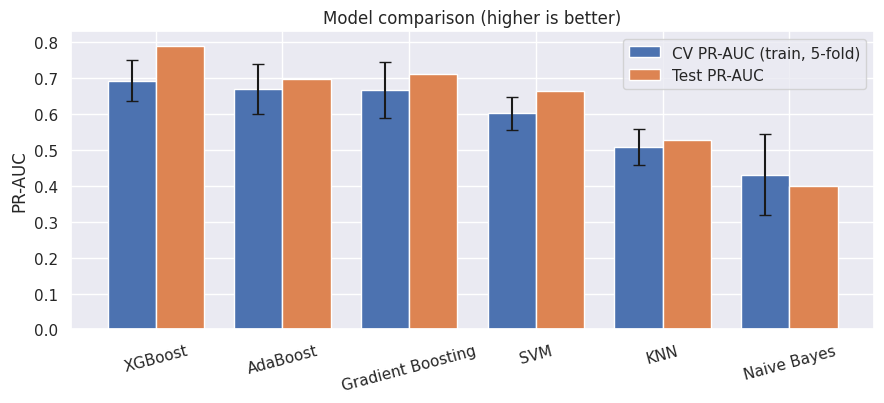

In [11]:
comparison = pd.DataFrame({
    'CV PR-AUC (mean)':  cv_mean['PR-AUC'],
    'CV PR-AUC (std)':   cv_std['PR-AUC'],
    'Test PR-AUC':       test_table['PR-AUC'],
    'Test ROC-AUC':      test_table['ROC-AUC'],
    'Test Recall':       test_table['Recall'],
    'Test Precision':    test_table['Precision'],
    'Test F1':           test_table['F1'],
    'Train F1':          test_table['Train F1'],
}).sort_values('CV PR-AUC (mean)', ascending=False)
comparison.insert(0, 'Rank (CV PR-AUC)', range(1, len(comparison) + 1))
display(comparison.round(3))

# ---- the decision, made by code from the numbers above ----
best_name = comparison.index[0]
best_row  = comparison.loc[best_name]
log.info(f'BEST MODEL by CV PR-AUC: {best_name} ({best_row["CV PR-AUC (mean)"]:.3f} +/- {best_row["CV PR-AUC (std)"]:.3f})')

# is the winner clearly ahead, or only inside the noise?
within_noise = [m for m in comparison.index[1:]
                if comparison.loc[m, 'CV PR-AUC (mean)'] >= best_row['CV PR-AUC (mean)'] - best_row['CV PR-AUC (std)']]
if within_noise:
    print(f'Careful: {within_noise} are within one standard deviation of {best_name}. '
          f'With only 176 bankrupt training companies we cannot say they are really worse.')
else:
    print(f'{best_name} is clearly ahead of the other models (more than one standard deviation).')

test_best = comparison['Test PR-AUC'].idxmax()
print('The test set', 'AGREES' if test_best == best_name else f'prefers {test_best}', f'(highest test PR-AUC: {test_best}).')

# ---- picture: CV (with error bars) next to test ----
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(comparison)); w = 0.38
ax.bar(x - w/2, comparison['CV PR-AUC (mean)'], w, yerr=comparison['CV PR-AUC (std)'], capsize=4, label='CV PR-AUC (train, 5-fold)')
ax.bar(x + w/2, comparison['Test PR-AUC'], w, label='Test PR-AUC')
ax.set_xticks(x); ax.set_xticklabels(comparison.index, rotation=15)
ax.set_ylabel('PR-AUC'); ax.set_title('Model comparison (higher is better)'); ax.legend()
plt.tight_layout(); save_fig('plot_05_model_comparison.png'); plt.show()

comparison.round(4).to_csv(OUT_DIR / 'model_comparison.csv')
cv_folds.round(4).to_csv(OUT_DIR / 'cv_fold_results.csv', index=False)
test_table.round(4).to_csv(OUT_DIR / 'test_set_results.csv')

**What to say in the viva:** read the table top to bottom. The rank comes from the *training-set* cross-validation, the test columns confirm it. Then read the note printed above: if other models are inside one standard deviation, say clearly that the data is too small to separate them, and that we pick the top one because it has the best score and is **not worse on the test set**.

**Precision / recall trade-off:** the weighted models catch most bankruptcies (high recall) but also raise many false alarms (low precision). That is the price of the class weights; it moves the balance, it does not make the ranking better. A bank would choose the cut-off from the cost of each kind of mistake (next step).

---
## Step 7: Decision threshold of the best model
**What we do:** the model gives every company a **probability of bankruptcy**. By default "≥ 0.5 means bankrupt". We try the cut-offs 0.1 to 0.9.

**Why change it?** For a rare class 0.5 is rarely the best cut-off. A low cut-off flags more companies (more bankruptcies caught, more false alarms); a high cut-off is stricter.

**How we avoid cheating:** the table is computed from the **out-of-fold probabilities of the training set** (from Step 5), *not* from the test set. So the cut-off is chosen on validation data. The test set is used once, at the end, only to show what would have happened.

,precision,recall,F1,flagged
threshold,,,,
0.1,0.117,0.949,0.208,1430
0.2,0.158,0.898,0.269,999
0.3,0.197,0.864,0.321,771
0.4,0.235,0.847,0.368,634
0.5,0.282,0.795,0.416,497
0.6,0.338,0.750,0.466,391
0.7,0.434,0.716,0.541,290
0.8,0.592,0.642,0.616,191
0.9,0.820,0.517,0.634,111


XGBoost: the cut-off with the best F1 on the training CV is 0.9. Same cut-off applied once to the test set:


,precision,recall,F1
default 0.5,0.303,0.841,0.446
best on train CV (0.9),1.000,0.500,0.667


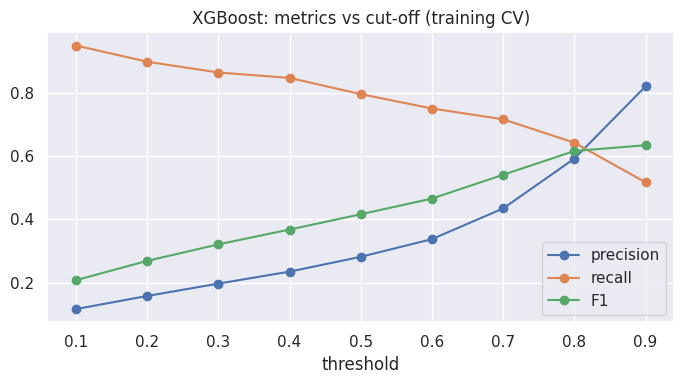

Note: 0.9 is the edge of the table, so the real peak may lie beyond it - treat the cut-off as a rough guide.
09:17:01 | Threshold study for XGBoost: best CV cut-off = 0.9; final predictor uses DECISION_THRESHOLD = 0.5


In [12]:
oof = oof_prob[best_name]
rows = []
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (oof >= th).astype(int)
    rows.append({'threshold': th, 'precision': precision_score(y_train, p, zero_division=0),
                 'recall': recall_score(y_train, p), 'F1': f1_score(y_train, p), 'flagged': int(p.sum())})
th_df = pd.DataFrame(rows).set_index('threshold')
display(th_df.round(3))

best_th = th_df['F1'].idxmax()
test_prob = models[best_name].predict_proba(X_test)[:, 1]
show = pd.DataFrame({
    f'default {DECISION_THRESHOLD}': [precision_score(y_test, test_prob >= DECISION_THRESHOLD, zero_division=0),
                                      recall_score(y_test, test_prob >= DECISION_THRESHOLD),
                                      f1_score(y_test, test_prob >= DECISION_THRESHOLD)],
    f'best on train CV ({best_th})': [precision_score(y_test, test_prob >= best_th, zero_division=0),
                                      recall_score(y_test, test_prob >= best_th),
                                      f1_score(y_test, test_prob >= best_th)]},
    index=['precision', 'recall', 'F1']).T
print(f'{best_name}: the cut-off with the best F1 on the training CV is {best_th}. Same cut-off applied once to the test set:')
display(show.round(3))

th_df[['precision', 'recall', 'F1']].plot(marker='o', figsize=(7, 4), title=f'{best_name}: metrics vs cut-off (training CV)')
plt.tight_layout(); save_fig('plot_06_threshold_study.png'); plt.show()
if best_th in (th_df.index.min(), th_df.index.max()):
    print(f'Note: {best_th} is the edge of the table, so the real peak may lie beyond it - treat the cut-off as a rough guide.')
log.info(f'Threshold study for {best_name}: best CV cut-off = {best_th}; final predictor uses DECISION_THRESHOLD = {DECISION_THRESHOLD}')

**Note:** the final predictor below keeps `DECISION_THRESHOLD = 0.5`, so all numbers match the six model notebooks and the viva guide. If the bank prefers to catch more bankruptcies, change that one number in the settings cell.

---
## Step 8: Which financial ratios matter? (best model)
Tree models count how much each feature helped to make good splits. The longer the bar, the more the model used that ratio.

**Careful:** importance shows which ratios the model *relies on*, not which ratios *cause* bankruptcy.

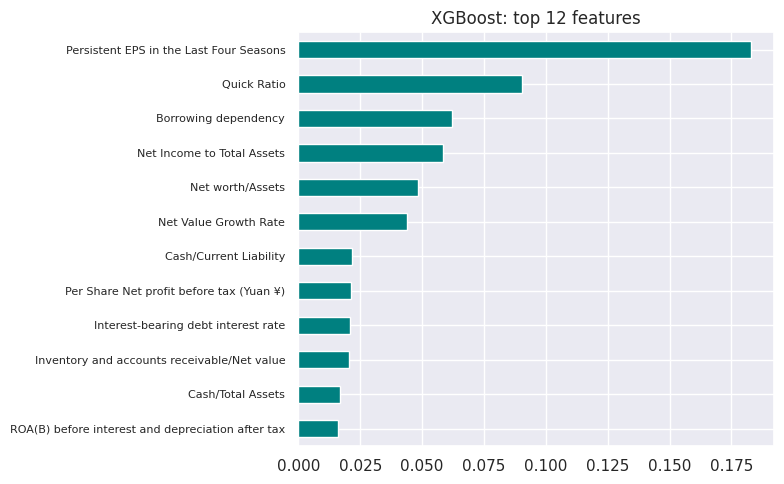

In [13]:
best_model = models[best_name]
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values().tail(12)
    imp.plot(kind='barh', figsize=(8, 5), color='teal', title=f'{best_name}: top 12 features')
    plt.tick_params(axis='y', labelsize=8)
    plt.tight_layout(); save_fig('plot_07_feature_importance.png'); plt.show()
else:
    print(f'{best_name} has no built-in feature importance (only tree models have it).')

---
## Step 9: Save the final model
**What we do:** save the winning model together with the preprocessing numbers and the cut-off in **one file**, so the demo can load it without re-training.

**Why the model was trained only on the training set:** the test set must stay unseen until the end. The test companies were used only for scoring.

*(A `.joblib` file is a Python pickle: only open files you made yourself.)*

In [14]:
bundle = {'model_name': best_name, 'model': models[best_name], 'preprocessing': art,
          'threshold': DECISION_THRESHOLD, 'seed': SEED}
joblib.dump(bundle, OUT_DIR / 'best_model.joblib')
log.info(f'Saved best model ({best_name}) to results/outputs/best_model.joblib')

09:17:02 | Saved best model (XGBoost) to results/outputs/best_model.joblib


---
## Step 10: Predict new companies from RAW financial ratios
**The problem:** a new company comes as raw numbers, but the models were trained on scaled numbers in a fixed column order.

**The solution — `transform_raw()` does exactly what Step 1 did to the training data:**
1. strip the spaces from the column names
2. keep only the 62 raw columns the model uses
3. scale each ratio with the **training** `min` and `max` — *never* with the new company's own numbers
4. build `Profitability Ratio` the same way
5. put the 63 columns in the training order

If a ratio is missing it is replaced by the **median of the training companies** (and we tell you). If a value is **outside the range seen in training** (scaled < 0 or > 1) we warn you, because the model has never seen such a company and the answer is less reliable.

In [15]:
def transform_raw(raw_new, art):
    # raw ratios (any number of companies)  ->  the 63 scaled model inputs
    d = raw_new.copy()
    d.columns = d.columns.astype(str).str.strip()
    notes = []

    missing = [c for c in art['kept_raw_columns'] if c not in d.columns]
    if missing:
        notes.append(f'{len(missing)} ratio(s) not given -> filled with the training median')
        for c in missing:
            d[c] = art['raw_median'][c]

    mn = pd.Series(art['scaler_min']); mx = pd.Series(art['scaler_max'])
    Xs = (d[art['kept_raw_columns']] - mn) / (mx - mn)         # SAME min/max as the training data

    outside = ((Xs < 0) | (Xs > 1)).sum(axis=1)
    for i, k in enumerate(outside.values, start=1):
        if k:
            notes.append(f'company {i}: {k} ratio(s) outside the range seen in training (scaled <0 or >1)')

    Xs['Profitability Ratio'] = (Xs['ROA(C) before interest and depreciation before interest']
                                 / (Xs['ROA(A) before interest and % after tax'] + 0.0001))
    return Xs[art['feature_order']], notes

def predict_companies(raw_new, bundle=bundle):
    # probability of bankruptcy and the verdict of the final (best) model
    X_new, notes = transform_raw(raw_new, bundle['preprocessing'])
    prob = bundle['model'].predict_proba(X_new)[:, 1]
    out = pd.DataFrame({'company': range(1, len(X_new) + 1),
                        'probability of bankruptcy %': (prob.astype(float) * 100).round(1),
                        'model says': np.where(prob >= bundle['threshold'], 'BANKRUPT', 'HEALTHY')})
    return out, X_new, notes

# ---------- sanity test: the raw -> scaled conversion must give the same numbers as the saved dataset
check_rows = raw.sample(5, random_state=1)
check_rows = check_rows[check_rows.index.isin(final_df.index)]
if len(check_rows):
    Xc, _ = transform_raw(check_rows.drop(columns=[TARGET]), art)
    assert np.allclose(Xc.values, final_df.loc[check_rows.index, art['feature_order']].values)
    log.info('Check passed: transform_raw() on raw rows == the scaled rows in final_processed_data.csv')

09:17:02 | Check passed: transform_raw() on raw rows == the scaled rows in final_processed_data.csv


### 10a. The sample companies (raw file given with the project)
`data/external/sample_data_example.csv` holds 6 companies in raw units. The file has the real answer in `Bankrupt?`, so we can check the model.

In [16]:
sample = pd.read_csv(SAMPLE_CSV)
sample.columns = sample.columns.str.strip()
sample_y = sample[TARGET].astype(int).values if TARGET in sample.columns else None

result, X_sample, notes = predict_companies(sample.drop(columns=[TARGET], errors='ignore'))
if sample_y is not None:
    result['real answer'] = np.where(sample_y == 1, 'BANKRUPT', 'HEALTHY')
    result['correct?'] = np.where((result['model says'] == result['real answer']), 'yes', 'NO')
print(f'Final model: {bundle["model_name"]}  (cut-off {bundle["threshold"]})')
for n in notes: print('NOTE:', n)
if sample_y is not None:
    print(f'Correct: {(result["correct?"] == "yes").sum()} of {len(result)}')
display(result)
result.to_csv(OUT_DIR / 'sample_predictions.csv', index=False)

Final model: XGBoost  (cut-off 0.5)
Correct: 4 of 6


,company,probability of bankruptcy %,model says,real answer,correct?
0,1,2.7,HEALTHY,HEALTHY,yes
1,2,81.1,BANKRUPT,HEALTHY,NO
2,3,9.3,HEALTHY,HEALTHY,yes
3,4,38.4,HEALTHY,BANKRUPT,NO
4,5,91.0,BANKRUPT,BANKRUPT,yes
5,6,83.3,BANKRUPT,BANKRUPT,yes


### 10b. What do all six models say about these companies?
Each model gives its own answer (its own `predict()`, as in the six model notebooks). **If the models disagree, trust the ranking from Step 6 more than a single answer** — and remember that 6 companies is far too few to judge a model.

In [17]:
rows = {}
for name, model in models.items():
    prob = model.predict_proba(X_sample)[:, 1]
    ans  = model.predict(X_sample)
    rows[name] = [f'{p*100:5.1f}% {"B" if a == 1 else "H"}' for p, a in zip(prob, ans)]
all6 = pd.DataFrame(rows, index=[f'company {i}' for i in range(1, len(X_sample) + 1)])
if sample_y is not None:
    all6.insert(0, 'real answer', np.where(sample_y == 1, 'B', 'H'))
display(all6)
if sample_y is not None:
    correct = {n: int((models[n].predict(X_sample) == sample_y).sum()) for n in models}
    print('Correct out of', len(sample_y), '->', correct)
print('B = model says bankrupt, H = model says healthy; the % is the probability of bankruptcy.')

,real answer,SVM,XGBoost,KNN,Gradient Boosting,AdaBoost,Naive Bayes
company 1,H,0.2% H,2.7% H,0.0% H,2.0% H,16.9% H,0.0% H
company 2,H,1.2% H,81.1% B,0.0% H,87.3% B,73.3% B,2.6% H
company 3,H,2.0% H,9.3% H,0.0% H,12.9% H,28.6% H,0.0% H
company 4,B,0.2% H,38.4% H,100.0% B,51.1% B,32.0% H,0.0% H
company 5,B,11.0% B,91.0% B,100.0% B,90.1% B,67.2% B,0.0% H
company 6,B,29.2% B,83.3% B,100.0% B,89.0% B,63.0% B,34.4% H


Correct out of 6 -> {'SVM': 5, 'XGBoost': 4, 'KNN': 6, 'Gradient Boosting': 5, 'AdaBoost': 4, 'Naive Bayes': 3}
B = model says bankrupt, H = model says healthy; the % is the probability of bankruptcy.


### 10c. Try your own company
Type raw values for any ratios you want to change, in the **raw units of the dataset** (most ratios are between 0 and 1). You can write only part of a name (it must match exactly one column). **Ratios you leave out are replaced by the training median**, so with `MY_COMPANY = {}` you get the answer for a *typical* company.

In [18]:
def find_column(part, columns):
    exact = [c for c in columns if part.lower() == c.lower()]
    if len(exact) == 1:                       # a full column name always wins
        return exact[0]
    hits = [c for c in columns if part.lower() in c.lower()]
    if len(hits) != 1:
        raise ValueError(f'"{part}" matches {len(hits)} columns: {hits[:5]} - use a longer name')
    return hits[0]

def my_company(changes, start_from=None):
    # start_from = a row (0..5) of the sample file to copy, or None for a typical company
    base = ({c: art['raw_median'][c] for c in art['kept_raw_columns']} if start_from is None
            else sample.iloc[start_from][art['kept_raw_columns']].astype(float).to_dict())
    for name, value in changes.items():
        base[find_column(name, art['kept_raw_columns'])] = value
    return pd.DataFrame([base])

MY_COMPANY = {}            # <- type your own values, e.g. {'Debt ratio %': 0.35, 'Net Income to Total Assets': 0.78}
START_FROM = None          # <- or copy sample company number 0..5 and change a few ratios

res, _, notes = predict_companies(my_company(MY_COMPANY, START_FROM))
for n in notes: print('NOTE:', n)
display(res)

,company,probability of bankruptcy %,model says
0,1,2.0,HEALTHY


**What-if example:** take sample company 1 and move **one** ratio from the typical *healthy* value to the typical *bankrupt* value (both medians of the training data). We use the raw ratio the final model relies on most (Step 8), so the effect is visible.

In [19]:
if hasattr(best_model, 'feature_importances_'):
    ranked = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    what_if_col = next(c for c in ranked.index if c in art['kept_raw_columns'])   # skip the engineered ratio
else:
    what_if_col = 'Net Income to Total Assets'

lo, hi = art['scaler_min'][what_if_col], art['scaler_max'][what_if_col]
to_raw = lambda scaled: scaled * (hi - lo) + lo                   # undo the MinMax scaling
healthy_raw  = to_raw(final_df.loc[final_df[TARGET] == 0, what_if_col].median())
bankrupt_raw = to_raw(final_df.loc[final_df[TARGET] == 1, what_if_col].median())

rows = []
for value in np.linspace(healthy_raw, bankrupt_raw, 5):
    r, _, _ = predict_companies(my_company({what_if_col: value}, start_from=0))
    rows.append({what_if_col + ' (raw)': round(float(value), 4),
                 'probability of bankruptcy %': r.loc[0, 'probability of bankruptcy %'],
                 'model says': r.loc[0, 'model says']})
print(f'Sample company 1: only "{what_if_col}" changes (healthy median -> bankrupt median)')
display(pd.DataFrame(rows))

Sample company 1: only "Persistent EPS in the Last Four Seasons" changes (healthy median -> bankrupt median)


,Persistent EPS in the Last Four Seasons (raw),probability of bankruptcy %,model says
0,0.2253,3.6,HEALTHY
1,0.2180,3.6,HEALTHY
2,0.2106,5.0,HEALTHY
3,0.2033,7.2,HEALTHY
4,0.1959,8.7,HEALTHY


---
## Summary and Reflection

In [20]:
summary = comparison[['Rank (CV PR-AUC)', 'CV PR-AUC (mean)', 'Test PR-AUC', 'Test Recall', 'Test Precision', 'Test F1']]
print(f'Best model: {best_name}')
print(f'  CV PR-AUC {best_row["CV PR-AUC (mean)"]:.3f} +/- {best_row["CV PR-AUC (std)"]:.3f} | '
      f'Test PR-AUC {best_row["Test PR-AUC"]:.3f} | Test recall {best_row["Test Recall"]:.3f} | '
      f'Test precision {best_row["Test Precision"]:.3f}')
display(summary.round(3))
log.info('Pipeline finished. Files are in results/outputs, results/eda_visualizations and results/logs')

Best model: XGBoost
  CV PR-AUC 0.694 +/- 0.057 | Test PR-AUC 0.791 | Test recall 0.841 | Test precision 0.303


,Rank (CV PR-AUC),CV PR-AUC (mean),Test PR-AUC,Test Recall,Test Precision,Test F1
Model,,,,,,
XGBoost,1,0.694,0.791,0.841,0.303,0.446
AdaBoost,2,0.671,0.699,0.909,0.244,0.385
Gradient Boosting,3,0.667,0.713,0.818,0.319,0.459
SVM,4,0.602,0.665,0.886,0.232,0.368
KNN,5,0.510,0.527,0.159,1.000,0.275
Naive Bayes,6,0.432,0.400,0.341,0.469,0.395


09:17:02 | Pipeline finished. Files are in results/outputs, results/eda_visualizations and results/logs


### Limitations (say these before the examiner asks)
1. **Very few bankrupt companies:** 176 for training and **44 for testing**. One company moves recall by 2.3 points, so small differences between models are noise.
2. **Small data leakage in the scaler:** the group pipeline fitted the MinMax scaler (and the correlation filter) on the **whole dataset before the split**, so the test companies slightly influenced the scaling. The effect is small, and tree models do not care about scaling, but a strict approach fits the scaler on the training set only. We kept the group's files so every number here matches the six model notebooks.
3. **Tuning and CV use the same training data:** the settings were chosen with 3-fold CV on the training set, so the 5-fold CV scores are slightly optimistic. That is why the untouched test set is still kept as a final check.
4. **Class weights trade precision for recall:** most weighted models flag many healthy companies. The cut-off should be chosen from the real cost of each mistake.
5. **Values outside the training range:** a new company far outside the training range is outside what the model has learned; `transform_raw()` warns about this.
6. **SVM probabilities:** `SVC.predict()` uses the decision function, while `predict_proba()` uses a separate probability fit, so for the SVM "probability ≥ 0.5" and `predict()` can disagree.

### What we would do next
Try SMOTE / under-sampling **inside** the CV folds (the model notebooks show it for each model), fit the scaler on the training data only, add Random Forest and Logistic Regression, and collect more bankrupt companies.